# A simple notebook demonstrating how to find SWOT swaths that intersect a given lat-lon bounding box

This notebook is based on an example taken from the [SWOT-OpenToolkit](https://github.com/SWOT-community/SWOT-OpenToolkit) developed by Jinbo Wang (Texas A&M).

This short notebook is useful for sanity checking when you're trying to find swaths in a specific region.

In [2]:
"""
Find the SWOT satellite fly-by time through a bounding box. 
The time will have uncertainty of tens of seconds to minutes depending on 
the size of the bounding box.

Make sure download the two shapefile associated with the SWOT orbit data from the aviso website. You can use the included script to download the data.

    bash download_swot_orbit.sh

Usage:
    python find_swot_passes_science.py -sw_corner -130.0 35.0 -ne_corner -125.0 40.0 -output_filename /tmp/test.png

1st Author: Jinbo Wang
Date: 2021-07-21
Adapted by: Tatsu Monkman
Date: 2025-01-24
"""

import geopandas as gpd
import pandas as pd
import shapely.geometry as geometry
from datetime import timedelta
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import box, LineString, Point
import numpy as np
import os,argparse

# To begin, download the shapefiles containing the lat/lon coordinates along SWOT swaths

### Key points:
- The geopandas compressed "shapefiles" containing the orbital tracks for the two SWOT orbital configurations can be downloaded from AVISO using the <code>download_swot_orbit_data.sh</code> bash script located in the <code>src</code> directory. 
- The compressed calval orbit shapefile is named <code>sph_calval_swath.zip</code> and corresponds to the orbital track that SWOT followed during the calibration/validation phase of the mission (~90 days from March 2023 to July 2023). 
- The compressed science orbit shapefile is named <code>sph_science_swath.zip</code> and corresponds to the orbital track that SWOT transitioned to after the calibration/validation phase was completed in July 2023 and currently follows now.
- Note that this script also downloads the nadir paths, which only includes the path of SWOT's nadir (i.e. doesn't include the KaRIn swaths to the left/right). The nadir paths are smaller 

In [3]:
# "calval" and "science" refer to SWOT's initial 1-day repeat calibration orbit and the 21-day repeat science orbit, respectively
orbit = "science"
#orbit = "calval"


# download the two shapefile associated with the SWOT orbit data from the aviso website
if os.path.exists("../orbit_data/sph_science_nadir.zip") is False or os.path.exists("../orbit_data/sph_science_swath.zip") is False:
    print("Please download the two shapefiles associated with the SWOT orbit data from the aviso website using the included script.\n")
    print("run bash download script using:")
    print("bash download_swot_orbit_data.sh\n")
    exit()
    
elif orbit == "calval":
    # Load the calval orbit shapefile
    gdf_orbit = gpd.read_file("../orbit_data/sph_calval_swath.zip")
    
elif orbit == "science":
    # Load the science orbit shapefile
    gdf_orbit = gpd.read_file("../orbit_data/sph_science_swath.zip")


# Next, specify the lat-lon limits for the bounding box over which you want to pull swaths

### Lat-lon boxes can just be specified by defining their Southwest / Northeast corners.
I just specify the coordinates of each corner using <code>[deg East, deg North]</code>

Some example domains:
<python>
    
    # Global 
    sw_corner = [-180.0, -90.0]
    ne_corner = [180.0, 90.0]
        
    # Hawaii
    corner = [-167, 0.0]
    corner = [-135.0, 45.0]
    
    # West Greenland
    sw_corner = [-56.55, 68.32]
    ne_corner = [-50., 72.5]

    # small Agulhas
    sw_corner = [10.0,  -42.0] # [degE, degN]
    ne_corner = [18.0, -36.0] # [degE, degN]
    
    # big Agulhas
    sw_corner = [5.0, -50.0]
    ne_corner = [30.0, -30.0]


</python>



### Let's find the orbits that cross the "big Agulhas" region as an example

- First, we need to define the bounding box ("<code>bbox</code>" below) as a shapely object that geopandas can understand
- Next we can use the orbit shapefile to find the paths that intersect the "bbox" using geopandas magic

In [4]:
# Rough East of Japan domain (Kuroshio-ish)
kuroshio_sw_corner = [140,15]
kuroshio_ne_corner = [170,40]

# Define the bounding box as a shapely object using our lat lon coordinates
bbox = geometry.box(kuroshio_sw_corner[0], kuroshio_sw_corner[1], kuroshio_ne_corner[0], kuroshio_ne_corner[1])
# Get the overlapping segments using geopandas magic
overlapping_segments = gdf_orbit[gdf_orbit.intersects(bbox)]



# Plot the bounding box + overlapping SWOT orbits as a sanity check

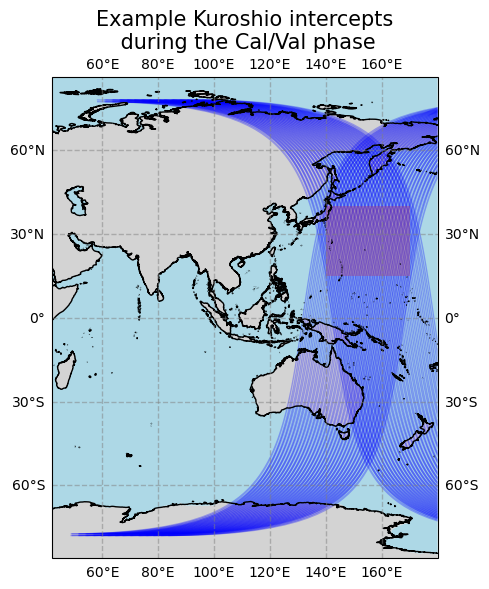

In [5]:
# Set up plot
subplot_kw = {'projection': ccrs.PlateCarree()}

fig, axs = plt.subplots(1,1,figsize=(50,6),subplot_kw=subplot_kw)

axs.set_title("Example Kuroshio intercepts\n during the Cal/Val phase",fontsize=15)

axs.add_feature(cfeature.COASTLINE.with_scale('10m'))
axs.add_feature(cfeature.LAND, edgecolor='none', facecolor='lightgray')
axs.add_feature(cfeature.OCEAN, edgecolor='none', facecolor='lightblue')
# Plot the shapefile data
#gdf.plot(ax=ax, transform=ccrs.PlateCarree())
gl = axs.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, color='gray', alpha=0.5, linestyle='--')

overlapping_segments.plot(ax=axs,alpha=0.3,color="b")

b = gpd.GeoSeries(bbox)
b.plot(ax=axs,color="r",alpha=0.2)


#axs.set_extent([-65, -10, 55, 90], crs=ccrs.PlateCarree())

plt.tight_layout()

plt.show()
plt.close()



## You can look at the "overlapping_segments" object to get a sense for what kind of information we have:

In [6]:
print(overlapping_segments)

     ID_PASS       START_TIME  \
1          2  Day 01 00:51:30   
23        17  Day 01 13:43:10   
41        30  Day 02 00:52:00   
63        45  Day 02 13:43:40   
81        58  Day 03 00:52:30   
103       73  Day 03 13:44:10   
122       86  Day 04 00:53:00   
144      101  Day 04 13:44:40   
163      114  Day 05 00:53:30   
185      129  Day 05 13:45:10   
204      142  Day 06 00:54:00   
223      155  Day 06 12:02:50   
226      157  Day 06 13:45:40   
242      168  Day 06 23:11:40   
245      170  Day 07 00:54:30   
264      183  Day 07 12:03:20   
267      185  Day 07 13:46:10   
283      196  Day 07 23:12:10   
286      198  Day 08 00:55:00   
304      211  Day 08 12:03:50   
307      213  Day 08 13:46:40   
323      224  Day 08 23:12:40   
326      226  Day 09 00:55:30   
344      239  Day 09 12:04:20   
347      241  Day 09 13:47:10   
363      252  Day 09 23:13:10   
366      254  Day 10 00:56:00   
385      267  Day 10 12:04:50   
404      280  Day 10 23:13:40   
407      2

Note that "START_TIME" is just a general estimate of the start time of a given pass, and may be out of date...

In [4]:
import xarray as xr 

test = xr.open_dataset(r"C:\Users\david\Documents\columbiaocean\SWOT-data-analysis\SWOT_L3\Expert_reproc_v3_US_california_science\cycle_001\SWOT_L3_LR_SSH_Expert_001_151_20230726T141050_20230726T150217_v3.0_cali.nc")

test.time.values #.ssha_filtered.plot()

array(['2023-07-26T14:44:42.012174336', '2023-07-26T14:44:42.324534528',
       '2023-07-26T14:44:42.636868480', ...,
       '2023-07-26T14:49:54.494744960', '2023-07-26T14:49:54.807281792',
       '2023-07-26T14:49:55.119943680'],
      shape=(1003,), dtype='datetime64[ns]')

In [6]:
 test1 = xr.open_dataset(r"C:\Users\david\Documents\columbiaocean\SWOT-data-analysis\SWOT_L3\Expert_reproc_v3_california_cal\cycle_474\SWOT_L3_LR_SSH_Expert_474_013_20230329T081513_20230329T090619_v3.0_cali.nc")

test1.time.values

array(['2023-03-29T08:48:51.458826496', '2023-03-29T08:48:51.769169792',
       '2023-03-29T08:48:52.079356288', ...,
       '2023-03-29T08:54:02.161327488', '2023-03-29T08:54:02.475338624',
       '2023-03-29T08:54:02.783732480'],
      shape=(1004,), dtype='datetime64[ns]')